Import the libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

Load the dataset

In [3]:
# Load the original dataset
df = pd.read_csv("./data/Frogs_MFCCs.csv")

# Remove accidental whitespace around column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")

Dataset loaded successfully!


Inspect the dataset

In [4]:
print("Dataset shape:", df.shape)

print("\nFirst five observations:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (7195, 26)

First five observations:


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,MFCCs_11,MFCCs_12,MFCCs_13,MFCCs_14,MFCCs_15,MFCCs_16,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,0.188654,-0.075622,-0.156436,0.082245,0.135752,-0.024017,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,0.270958,-0.095004,-0.254341,0.022786,0.163320,0.012022,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,0.266064,-0.072827,-0.237384,0.050791,0.207338,0.083536,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,0.267279,-0.162258,-0.317084,-0.011567,0.100413,-0.050224,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,0.332695,-0.100749,-0.298524,0.037439,0.219153,0.062837,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1



Column names:
['MFCCs_ 1', 'MFCCs_ 2', 'MFCCs_ 3', 'MFCCs_ 4', 'MFCCs_ 5', 'MFCCs_ 6', 'MFCCs_ 7', 'MFCCs_ 8', 'MFCCs_ 9', 'MFCCs_10', 'MFCCs_11', 'MFCCs_12', 'MFCCs_13', 'MFCCs_14', 'MFCCs_15', 'MFCCs_16', 'MFCCs_17', 'MFCCs_18', 'MFCCs_19', 'MFCCs_20', 'MFCCs_21', 'MFCCs_22', 'Family', 'Genus', 'Species', 'RecordID']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7195 entries, 0 to 7194
Data columns (total 26 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   MFCCs_ 1  7195 non-null   float64
 1   MFCCs_ 2  7195 non-null   float64
 2   MFCCs_ 3  7195 non-null   float64
 3   MFCCs_ 4  7195 non-null   float64
 4   MFCCs_ 5  7195 non-null   float64
 5   MFCCs_ 6  7195 non-null   float64
 6   MFCCs_ 7  7195 non-null   float64
 7   MFCCs_ 8  7195 non-null   float64
 8   MFCCs_ 9  7195 non-null   float64
 9   MFCCs_10  7195 non-null   float64
 10  MFCCs_11  7195 non-null   float64
 11  MFCCs_12  7195 non-null   float64
 12  MFCCs_13 

Check missing and duplicate values

In [5]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
MFCCs_ 1    0
MFCCs_ 2    0
MFCCs_ 3    0
MFCCs_ 4    0
MFCCs_ 5    0
MFCCs_ 6    0
MFCCs_ 7    0
MFCCs_ 8    0
MFCCs_ 9    0
MFCCs_10    0
MFCCs_11    0
MFCCs_12    0
MFCCs_13    0
MFCCs_14    0
MFCCs_15    0
MFCCs_16    0
MFCCs_17    0
MFCCs_18    0
MFCCs_19    0
MFCCs_20    0
MFCCs_21    0
MFCCs_22    0
Family      0
Genus       0
Species     0
RecordID    0
dtype: int64

Total missing values: 0

Duplicate rows: 0


Identify input and target columns

In [6]:
# Extract the 22 MFCC feature columns
feature_columns = [
    col for col in df.columns if col.startswith("MFCCs_")
]

# Select the target
target_column = "Species"

X = df[feature_columns]
y = df[target_column]

print("Number of input features:", len(feature_columns))
print("Number of observations:", len(df))
print("Number of species:", y.nunique())

print("\nSpecies:")
print(sorted(y.unique()))

Number of input features: 22
Number of observations: 7195
Number of species: 10

Species:
['AdenomeraAndre', 'AdenomeraHylaedactylus', 'Ameeregatrivittata', 'HylaMinuta', 'HypsiboasCinerascens', 'HypsiboasCordobae', 'LeptodactylusFuscus', 'OsteocephalusOophagus', 'Rhinellagranulosa', 'ScinaxRuber']


Examine class distribution

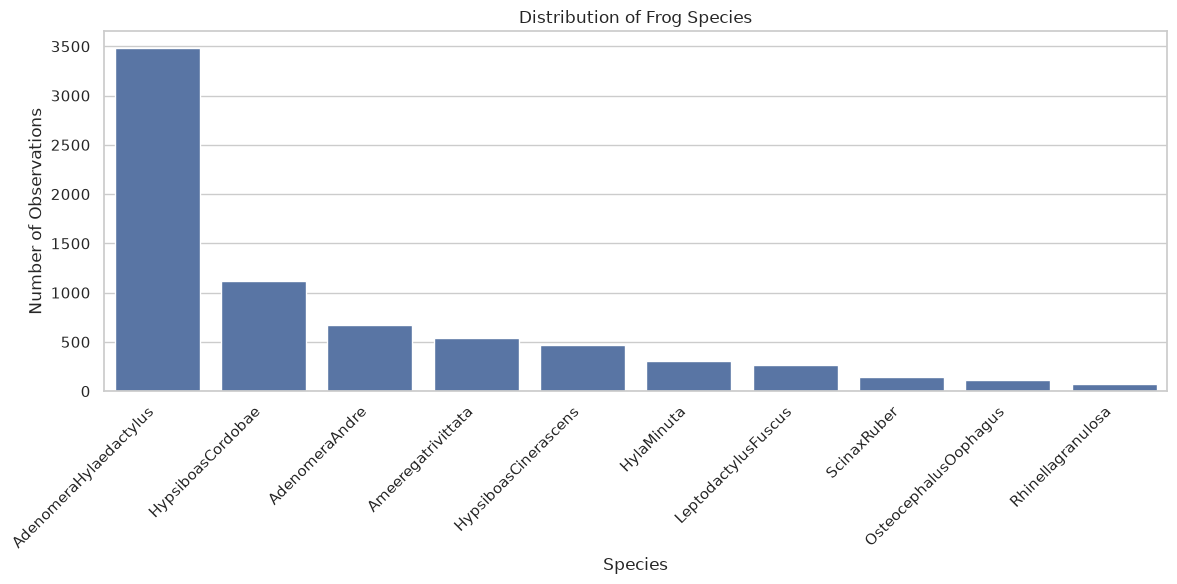

In [7]:
species_counts = df["Species"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=species_counts.index,
    y=species_counts.values
)

plt.title("Distribution of Frog Species")
plt.xlabel("Species")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Examine feature distributions

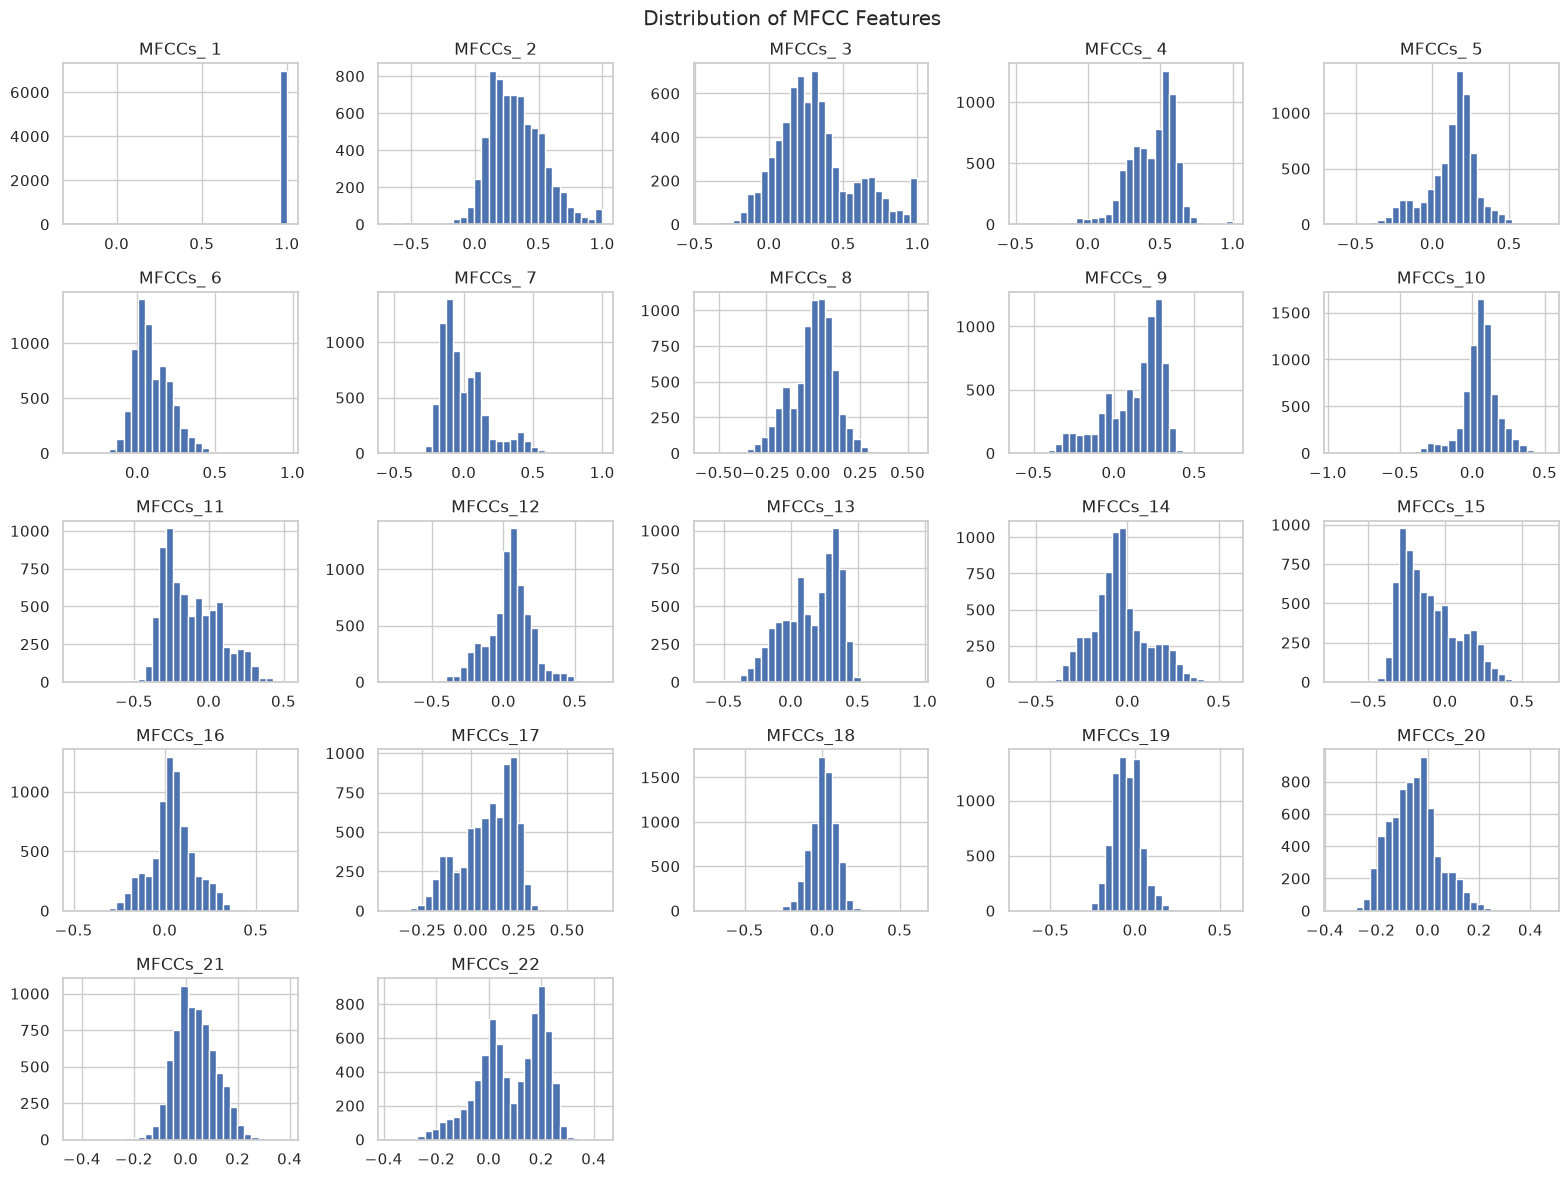

In [8]:
df[feature_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle("Distribution of MFCC Features")
plt.tight_layout()
plt.show()

Species distribution

In [9]:
species_summary = df.groupby("Species").agg(
    Number_of_Observations=("Species", "size"),
    Number_of_Recordings=("RecordID", "nunique")
).sort_values(
    by="Number_of_Observations",
    ascending=False
)

display(species_summary)

,Number_of_Observations,Number_of_Recordings
Species,,
AdenomeraHylaedactylus,3478,11
HypsiboasCordobae,1121,4
AdenomeraAndre,672,8
Ameeregatrivittata,542,5
HypsiboasCinerascens,472,4
HylaMinuta,310,11
LeptodactylusFuscus,270,4
ScinaxRuber,148,5
OsteocephalusOophagus,114,3


Visualize species distribution

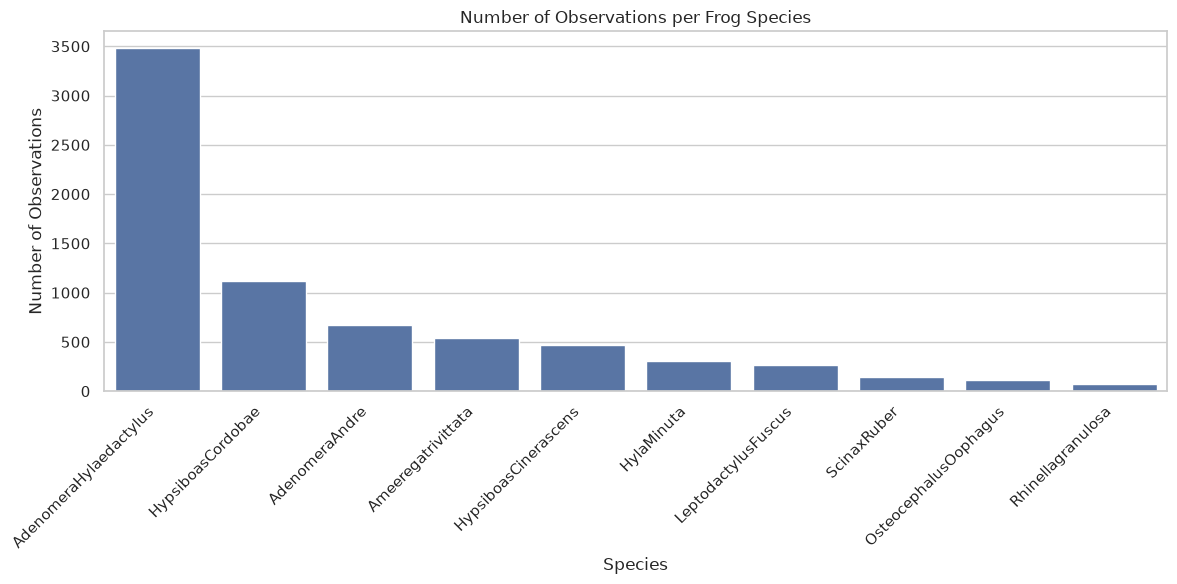

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=species_summary.reset_index(),
    x="Species",
    y="Number_of_Observations"
)

plt.title("Number of Observations per Frog Species")
plt.xlabel("Species")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Examine MFCC feature correlations

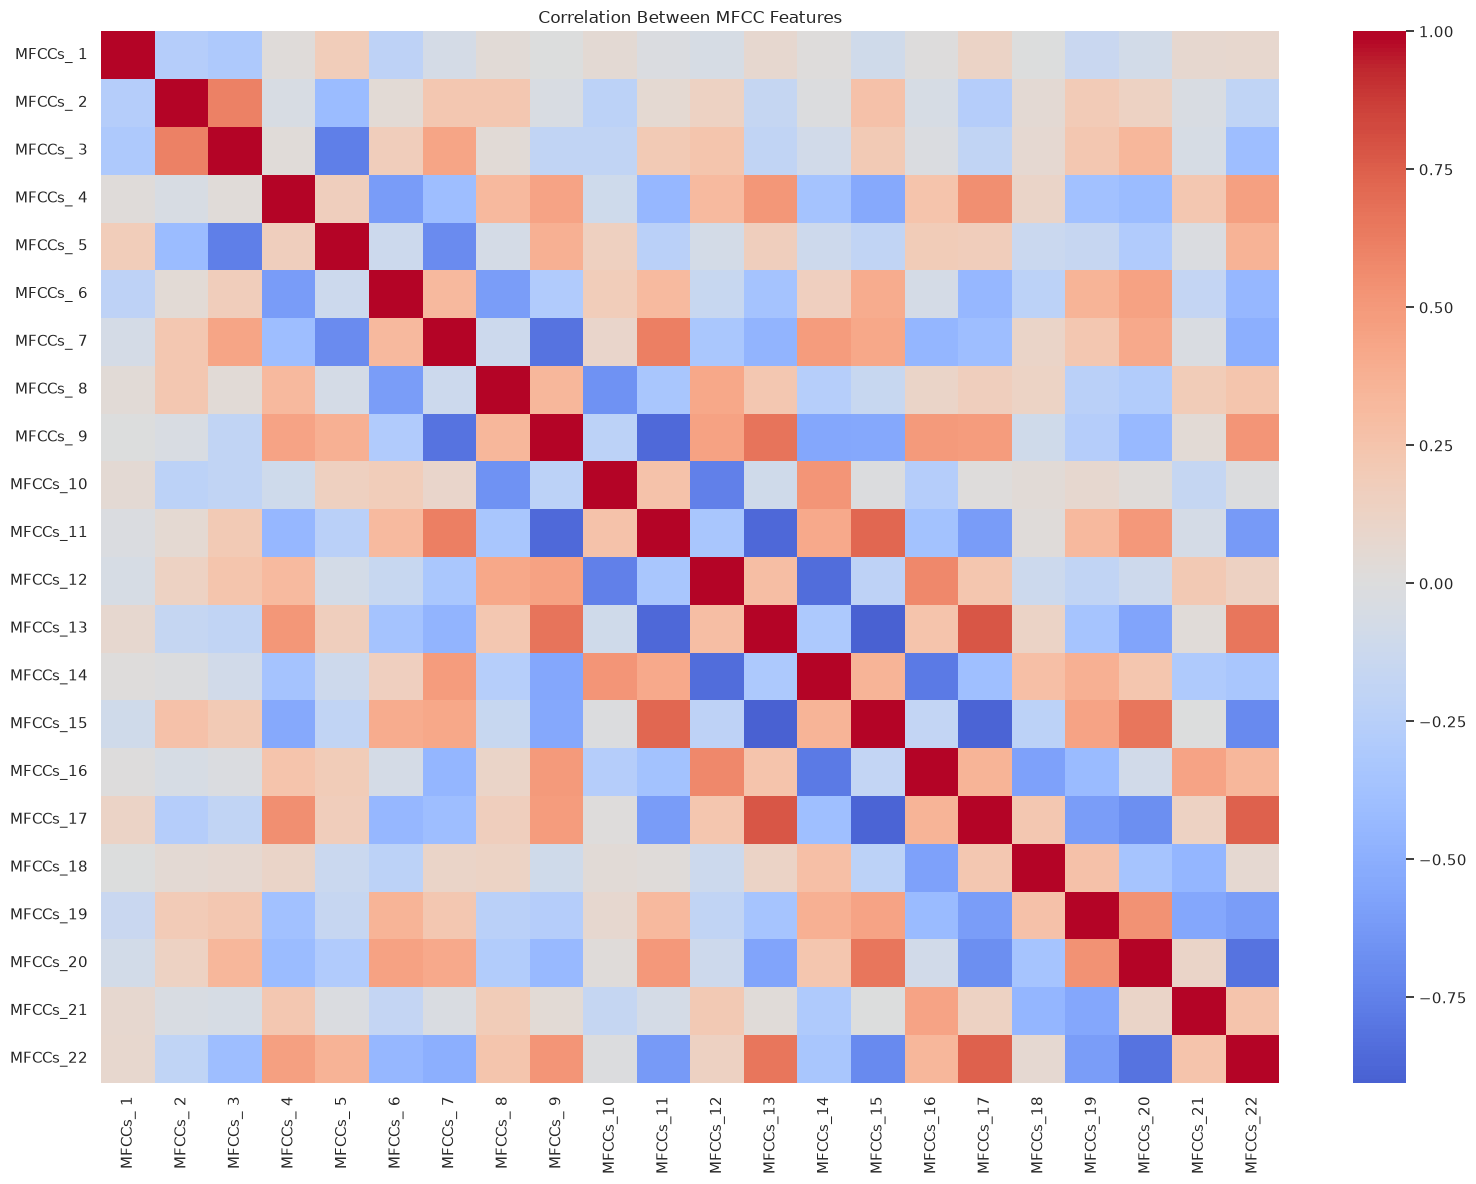

In [11]:
plt.figure(figsize=(16, 12))

correlation_matrix = X.corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Between MFCC Features")
plt.tight_layout()
plt.show()

Find a suitable group-based split

In [12]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np

X = df[feature_columns]
y = df["Species"]
groups = df["RecordID"]

all_species = sorted(y.unique())

# Original species proportions
original_distribution = (
    y.value_counts(normalize=True)
    .reindex(all_species)
)

splitter = GroupShuffleSplit(
    n_splits=5000,
    test_size=0.20,
    random_state=42
)

best_split = None
best_score = float("inf")

for train_idx, test_idx in splitter.split(X, y, groups):

    y_train_candidate = y.iloc[train_idx]
    y_test_candidate = y.iloc[test_idx]

    # Every species must appear in both sets
    if set(y_train_candidate.unique()) != set(all_species):
        continue

    if set(y_test_candidate.unique()) != set(all_species):
        continue

    # Calculate test-set class proportions
    test_distribution = (
        y_test_candidate.value_counts(normalize=True)
        .reindex(all_species, fill_value=0)
    )

    # Measure deviation from original proportions
    class_difference = np.abs(
        test_distribution - original_distribution
    ).sum()

    # Penalize splits far from 80:20
    size_difference = abs(
        len(test_idx) / len(df) - 0.20
    )

    score = class_difference + size_difference

    if score < best_score:
        best_score = score
        best_split = (train_idx, test_idx)

if best_split is None:
    raise ValueError("No suitable group split found.")

train_idx, test_idx = best_split

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting distribution:")
print(y_test.value_counts().sort_index())

print("\nTest-set class proportions:")
print(y_test.value_counts(normalize=True).sort_index())

train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

print("\nCommon recordings:",
      len(train_groups.intersection(test_groups)))

Training observations: 5622
Testing observations: 1573

Training distribution:
Species
AdenomeraAndre             603
AdenomeraHylaedactylus    2725
Ameeregatrivittata         385
HylaMinuta                 271
HypsiboasCinerascens       327
HypsiboasCordobae          755
LeptodactylusFuscus        255
OsteocephalusOophagus      111
Rhinellagranulosa           60
ScinaxRuber                130
Name: count, dtype: int64

Testing distribution:
Species
AdenomeraAndre             69
AdenomeraHylaedactylus    753
Ameeregatrivittata        157
HylaMinuta                 39
HypsiboasCinerascens      145
HypsiboasCordobae         366
LeptodactylusFuscus        15
OsteocephalusOophagus       3
Rhinellagranulosa           8
ScinaxRuber                18
Name: count, dtype: int64

Test-set class proportions:
Species
AdenomeraAndre            0.043865
AdenomeraHylaedactylus    0.478703
Ameeregatrivittata        0.099809
HylaMinuta                0.024793
HypsiboasCinerascens      0.092181
Hypsiboa

Cell 22 — Check class representation

In [13]:
print("Training class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

print("\nSpecies in training:", y_train.nunique())
print("Species in testing:", y_test.nunique())

Training class distribution:
Species
AdenomeraAndre             603
AdenomeraHylaedactylus    2725
Ameeregatrivittata         385
HylaMinuta                 271
HypsiboasCinerascens       327
HypsiboasCordobae          755
LeptodactylusFuscus        255
OsteocephalusOophagus      111
Rhinellagranulosa           60
ScinaxRuber                130
Name: count, dtype: int64

Testing class distribution:
Species
AdenomeraAndre             69
AdenomeraHylaedactylus    753
Ameeregatrivittata        157
HylaMinuta                 39
HypsiboasCinerascens      145
HypsiboasCordobae         366
LeptodactylusFuscus        15
OsteocephalusOophagus       3
Rhinellagranulosa           8
ScinaxRuber                18
Name: count, dtype: int64

Species in training: 10
Species in testing: 10


Verify there is no recording leakage

In [14]:
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

print("Training recordings:", len(train_groups))
print("Testing recordings:", len(test_groups))

print(
    "Common recordings:",
    len(train_groups.intersection(test_groups))
)

assert len(train_groups.intersection(test_groups)) == 0
assert y_train.nunique() == 10
assert y_test.nunique() == 10

print("\nAll split validation checks passed!")

Training recordings: 48
Testing recordings: 12
Common recordings: 0

All split validation checks passed!


In [15]:
# Examine how many independent recordings belong to each species
recording_summary = df.groupby("Species").agg(
    Total_Observations=("Species", "size"),
    Number_of_Recordings=("RecordID", "nunique")
)

# Calculate the average number of observations per recording
recording_summary["Avg_Observations_Per_Recording"] = (
    recording_summary["Total_Observations"] /
    recording_summary["Number_of_Recordings"]
)

display(recording_summary.sort_values(
    by="Number_of_Recordings"
))

,Total_Observations,Number_of_Recordings,Avg_Observations_Per_Recording
Species,,,
OsteocephalusOophagus,114,3,38.000000
LeptodactylusFuscus,270,4,67.500000
HypsiboasCinerascens,472,4,118.000000
HypsiboasCordobae,1121,4,280.250000
Ameeregatrivittata,542,5,108.400000
Rhinellagranulosa,68,5,13.600000
ScinaxRuber,148,5,29.600000
AdenomeraAndre,672,8,84.000000
AdenomeraHylaedactylus,3478,11,316.181818


Save Train-Test Split

In [16]:
import os
import numpy as np

# Create the models directory if it doesn't exist
os.makedirs("models", exist_ok=True)

# Save the selected train-test indices for reproducibility
np.savez(
    "models/data_split.npz",
    train_idx=train_idx,
    test_idx=test_idx
)

# Verify that the recordings do not overlap
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

assert len(train_groups.intersection(test_groups)) == 0
assert y_train.nunique() == 10
assert y_test.nunique() == 10

print("Train-test split saved successfully.")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training recordings:", len(train_groups))
print("Testing recordings:", len(test_groups))
print("Common recordings:", len(train_groups.intersection(test_groups)))

Train-test split saved successfully.
Training observations: 5622
Testing observations: 1573
Training recordings: 48
Testing recordings: 12
Common recordings: 0


### Implementation of Classification Models

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.base import clone

import time
import joblib

In [18]:
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib"
}

In [19]:
from sklearn.model_selection import StratifiedGroupKFold

# Get recording identifiers for the training observations
groups_train = groups.iloc[train_idx]

# Create recording-independent stratified folds
cv = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

# Generate the folds once, using training data only
cv_splits = list(
    cv.split(X_train, y_train, groups_train)
)

print("Group-aware cross-validation folds created.")

Group-aware cross-validation folds created.


Define the five classification models

In [20]:
RANDOM_STATE = 42

models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=3000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision Tree": Pipeline([
        ("classifier", DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("classifier", GaussianNB())
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            random_state=RANDOM_STATE
        ))
    ])

}

print("Classification models initialized:")

for model_name in models:
    print("-", model_name)

Classification models initialized:
- Logistic Regression
- Decision Tree
- KNN
- Naive Bayes
- SVM


Train all five models

In [21]:
from sklearn.calibration import CalibratedClassifierCV

trained_models = {}
training_times = {}

for model_name, model_pipeline in models.items():

    print(f"\nTraining {model_name}...")

    start_time = time.time()

    if model_name == "SVM":

        # Calibrate SVM to obtain probability estimates
        # The supplied folds keep recordings separate
        model = CalibratedClassifierCV(
            estimator=clone(model_pipeline),
            method="sigmoid",
            cv=cv_splits,
            ensemble=False
        )

    else:
        model = clone(model_pipeline)

    # Fit the model using training data only
    model.fit(X_train, y_train)

    end_time = time.time()

    # Store the fitted model and training duration
    trained_models[model_name] = model
    training_times[model_name] = end_time - start_time

    print(f"{model_name} trained successfully.")
    print(f"Training time: {end_time - start_time:.3f} seconds")


Training Logistic Regression...
Logistic Regression trained successfully.
Training time: 6.006 seconds

Training Decision Tree...
Decision Tree trained successfully.
Training time: 0.506 seconds

Training KNN...
KNN trained successfully.
Training time: 0.044 seconds

Training Naive Bayes...
Naive Bayes trained successfully.
Training time: 0.038 seconds

Training SVM...
SVM trained successfully.
Training time: 5.860 seconds


Model Evaluation

In [22]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

evaluation_results = []

for model_name, model in trained_models.items():

    # Generate predictions
    y_pred = model.predict(X_test)

    # Obtain predicted probabilities for multiclass AUC
    y_prob = model.predict_proba(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test,
        y_prob,
        labels=model.classes_,
        multi_class="ovr",
        average="macro"
    )

    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc,
        "Training Time (s)": training_times[model_name]
    })

    print(f"\n{'='*55}")
    print(f"Model: {model_name}")
    print(f"{'='*55}")

    print(f"Accuracy:  {accuracy:.4f}")
    print(f"AUC:       {auc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"MCC:       {mcc:.4f}")


Model: Logistic Regression
Accuracy:  0.8976
AUC:       0.9748
Precision: 0.9085
Recall:    0.8976
F1 Score:  0.9003
MCC:       0.8552

Model: Decision Tree
Accuracy:  0.8659
AUC:       0.8611
Precision: 0.8958
Recall:    0.8659
F1 Score:  0.8773
MCC:       0.8118

Model: KNN
Accuracy:  0.9059
AUC:       0.9367
Precision: 0.9245
Recall:    0.9059
F1 Score:  0.9092
MCC:       0.8671

Model: Naive Bayes
Accuracy:  0.8252
AUC:       0.9600
Precision: 0.8753
Recall:    0.8252
F1 Score:  0.8393
MCC:       0.7615

Model: SVM
Accuracy:  0.8792
AUC:       0.9813
Precision: 0.8731
Recall:    0.8792
F1 Score:  0.8655
MCC:       0.8306


Comparison table

In [23]:
results_df = pd.DataFrame(evaluation_results)

results_df = results_df.set_index("Model")

display(
    results_df.style.format("{:.4f}")
)

,Accuracy,AUC,Precision,Recall,F1 Score,MCC,Training Time (s)
Model,,,,,,,
Logistic Regression,0.8976,0.9748,0.9085,0.8976,0.9003,0.8552,6.0055
Decision Tree,0.8659,0.8611,0.8958,0.8659,0.8773,0.8118,0.5060
KNN,0.9059,0.9367,0.9245,0.9059,0.9092,0.8671,0.0444
Naive Bayes,0.8252,0.9600,0.8753,0.8252,0.8393,0.7615,0.0376
SVM,0.8792,0.9813,0.8731,0.8792,0.8655,0.8306,5.8603


Save all five trained models

In [24]:
# Save baseline models separately
baseline_model_dir = os.path.join("models", "baseline")

os.makedirs(baseline_model_dir, exist_ok=True)

for model_name, model in trained_models.items():

    file_path = os.path.join(
        baseline_model_dir,
        model_files[model_name]
    )

    joblib.dump(model, file_path)

    print(f"Saved baseline {model_name}: {file_path}")

Saved baseline Logistic Regression: models/baseline/logistic_regression.joblib
Saved baseline Decision Tree: models/baseline/decision_tree.joblib
Saved baseline KNN: models/baseline/knn.joblib
Saved baseline Naive Bayes: models/baseline/naive_bayes.joblib
Saved baseline SVM: models/baseline/svm.joblib


Model Evaluation: Confusion Matrix and Classification Report


Classification Report: Logistic Regression
                        precision    recall  f1-score   support

        AdenomeraAndre       0.41      0.35      0.38        69
AdenomeraHylaedactylus       1.00      0.98      0.99       753
    Ameeregatrivittata       0.78      0.94      0.85       157
            HylaMinuta       0.25      0.18      0.21        39
  HypsiboasCinerascens       0.92      0.90      0.91       145
     HypsiboasCordobae       0.99      0.90      0.94       366
   LeptodactylusFuscus       0.33      0.73      0.46        15
 OsteocephalusOophagus       0.08      0.33      0.12         3
     Rhinellagranulosa       0.50      0.88      0.64         8
           ScinaxRuber       0.78      1.00      0.88        18

              accuracy                           0.90      1573
             macro avg       0.60      0.72      0.64      1573
          weighted avg       0.91      0.90      0.90      1573



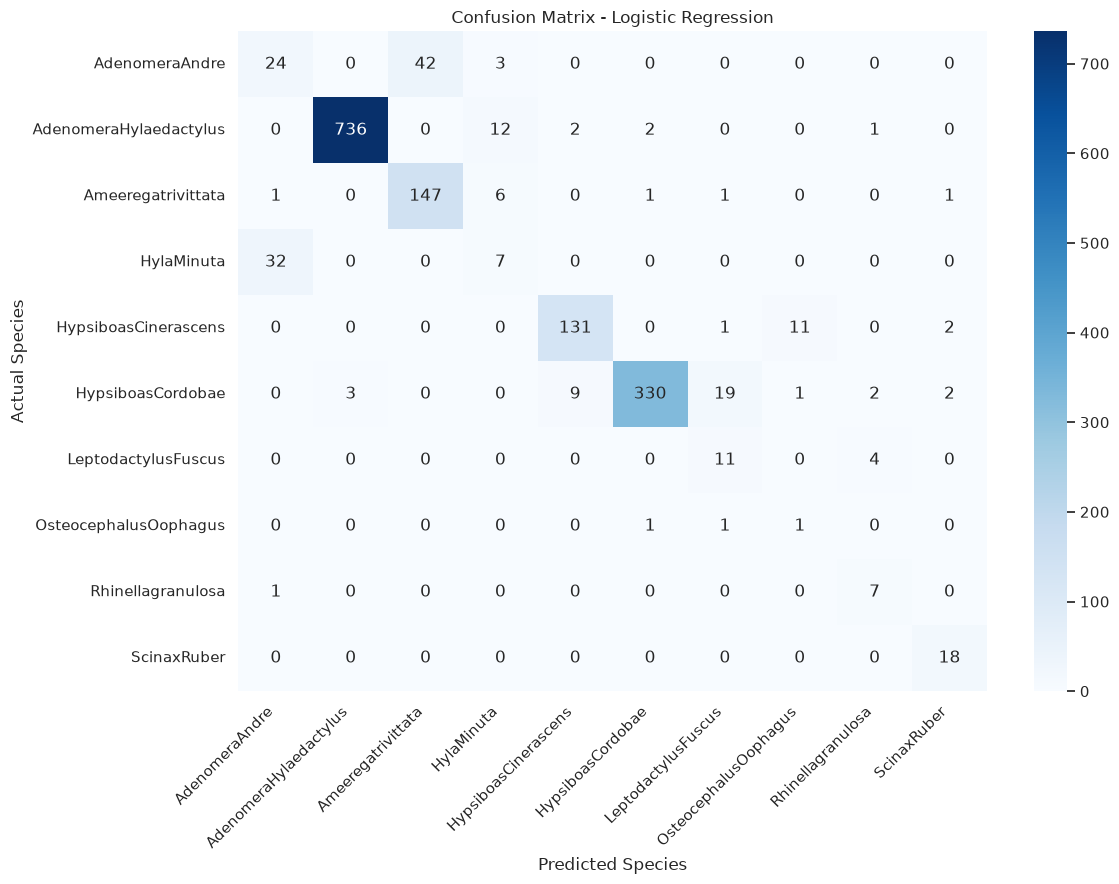


Classification Report: Decision Tree
                        precision    recall  f1-score   support

        AdenomeraAndre       0.51      0.59      0.55        69
AdenomeraHylaedactylus       1.00      0.96      0.98       753
    Ameeregatrivittata       0.79      0.89      0.83       157
            HylaMinuta       0.46      0.64      0.54        39
  HypsiboasCinerascens       0.88      0.70      0.78       145
     HypsiboasCordobae       0.92      0.83      0.87       366
   LeptodactylusFuscus       0.15      0.33      0.21        15
 OsteocephalusOophagus       0.14      1.00      0.25         3
     Rhinellagranulosa       0.75      0.75      0.75         8
           ScinaxRuber       0.44      0.67      0.53        18

              accuracy                           0.87      1573
             macro avg       0.60      0.74      0.63      1573
          weighted avg       0.90      0.87      0.88      1573



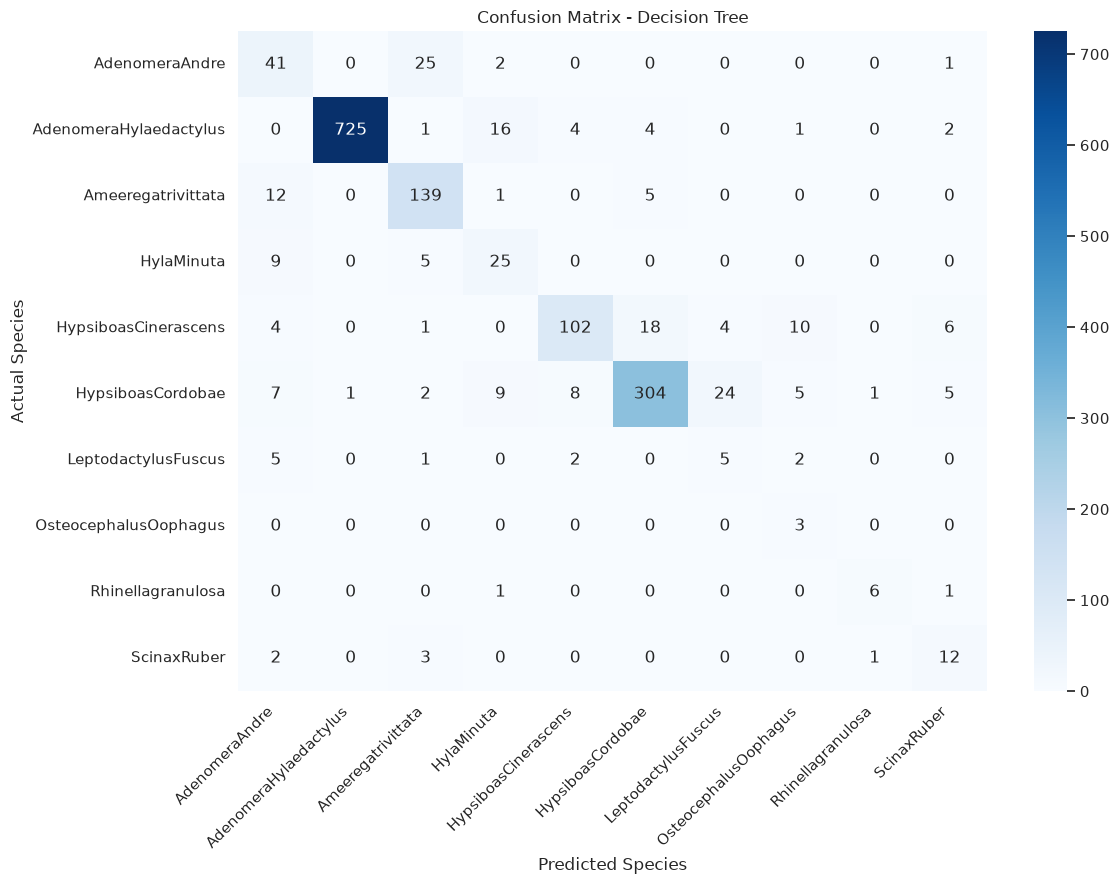


Classification Report: KNN
                        precision    recall  f1-score   support

        AdenomeraAndre       0.50      0.71      0.59        69
AdenomeraHylaedactylus       1.00      0.98      0.99       753
    Ameeregatrivittata       0.88      0.96      0.92       157
            HylaMinuta       0.23      0.08      0.12        39
  HypsiboasCinerascens       0.98      0.71      0.82       145
     HypsiboasCordobae       0.96      0.92      0.94       366
   LeptodactylusFuscus       0.30      0.87      0.44        15
 OsteocephalusOophagus       0.16      1.00      0.27         3
     Rhinellagranulosa       0.88      0.88      0.88         8
           ScinaxRuber       0.86      1.00      0.92        18

              accuracy                           0.91      1573
             macro avg       0.67      0.81      0.69      1573
          weighted avg       0.92      0.91      0.91      1573



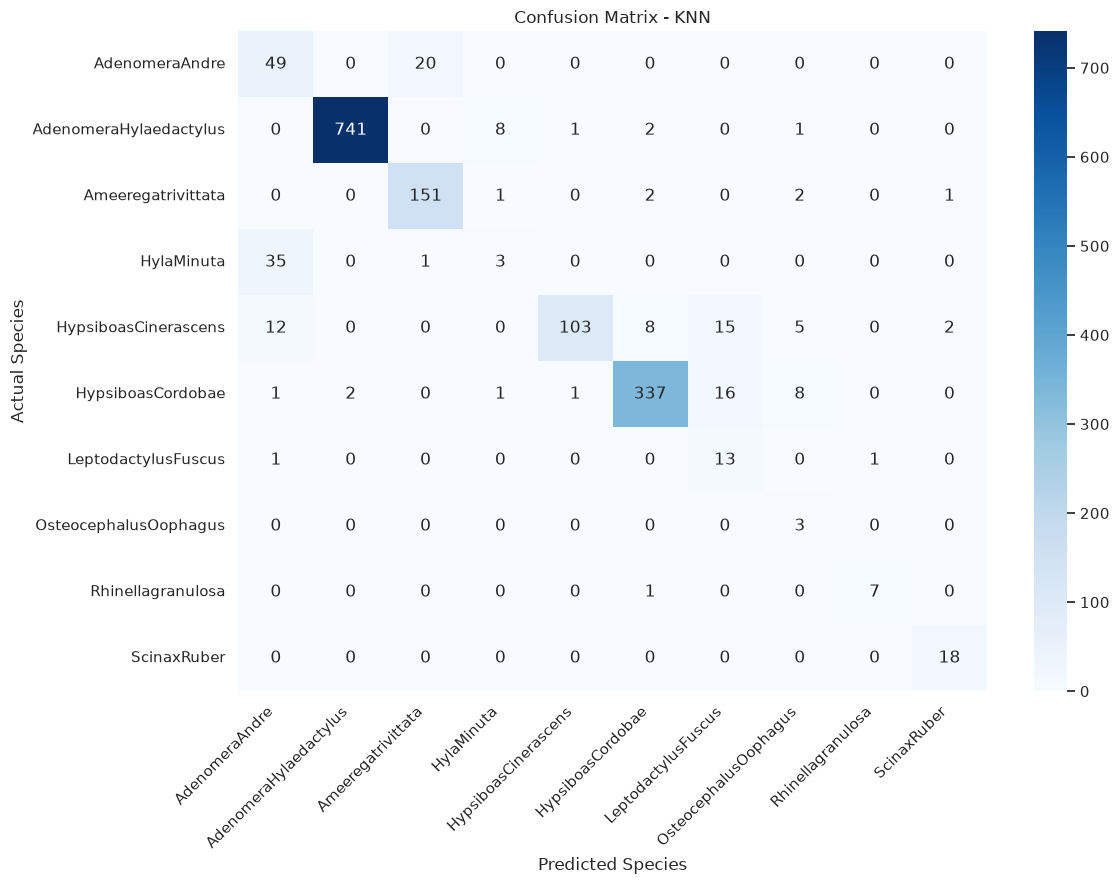


Classification Report: Naive Bayes
                        precision    recall  f1-score   support

        AdenomeraAndre       0.00      0.00      0.00        69
AdenomeraHylaedactylus       1.00      0.96      0.98       753
    Ameeregatrivittata       0.56      0.95      0.71       157
            HylaMinuta       0.00      0.00      0.00        39
  HypsiboasCinerascens       1.00      0.72      0.84       145
     HypsiboasCordobae       1.00      0.79      0.88       366
   LeptodactylusFuscus       0.37      0.47      0.41        15
 OsteocephalusOophagus       0.03      1.00      0.06         3
     Rhinellagranulosa       1.00      0.88      0.93         8
           ScinaxRuber       0.71      0.83      0.77        18

              accuracy                           0.83      1573
             macro avg       0.57      0.66      0.56      1573
          weighted avg       0.88      0.83      0.84      1573



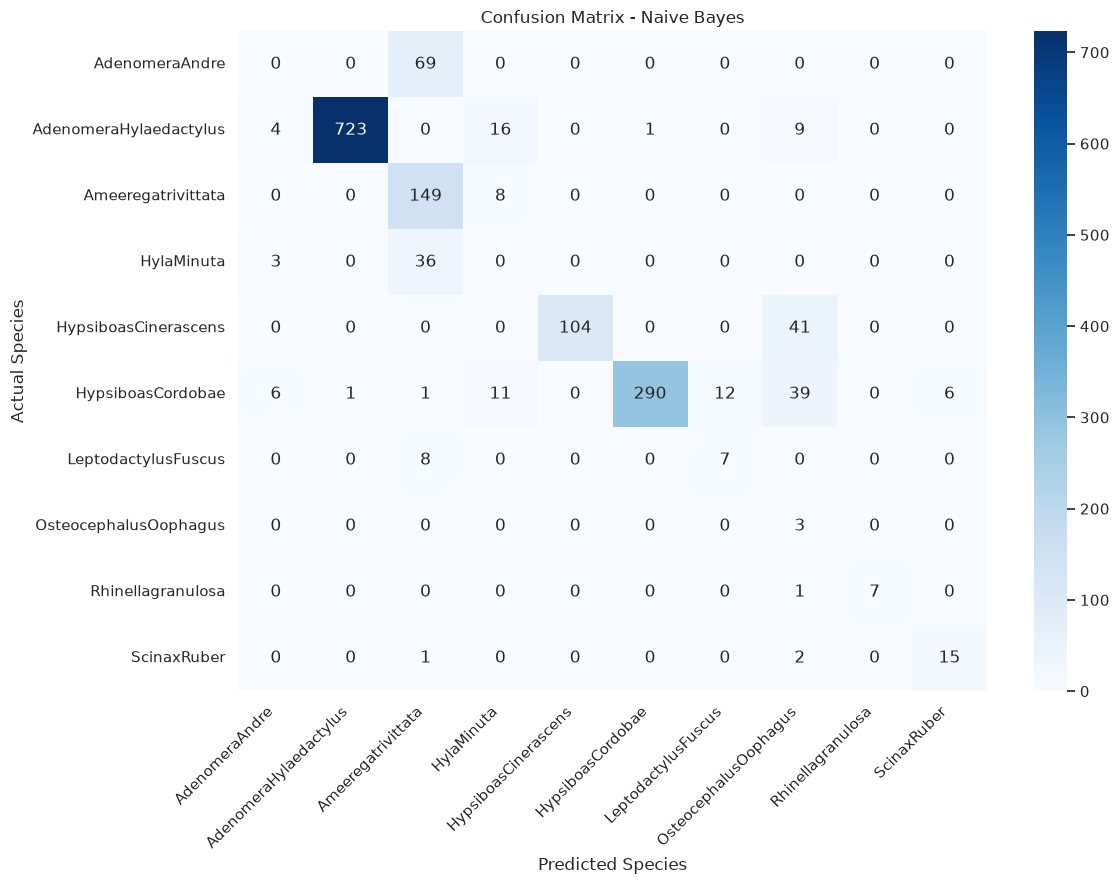


Classification Report: SVM
                        precision    recall  f1-score   support

        AdenomeraAndre       0.07      0.01      0.02        69
AdenomeraHylaedactylus       1.00      0.99      0.99       753
    Ameeregatrivittata       0.59      0.99      0.74       157
            HylaMinuta       0.33      0.13      0.19        39
  HypsiboasCinerascens       0.98      0.70      0.81       145
     HypsiboasCordobae       0.95      0.95      0.95       366
   LeptodactylusFuscus       0.39      1.00      0.57        15
 OsteocephalusOophagus       0.08      0.33      0.13         3
     Rhinellagranulosa       0.00      0.00      0.00         8
           ScinaxRuber       0.89      0.89      0.89        18

              accuracy                           0.88      1573
             macro avg       0.53      0.60      0.53      1573
          weighted avg       0.87      0.88      0.87      1573



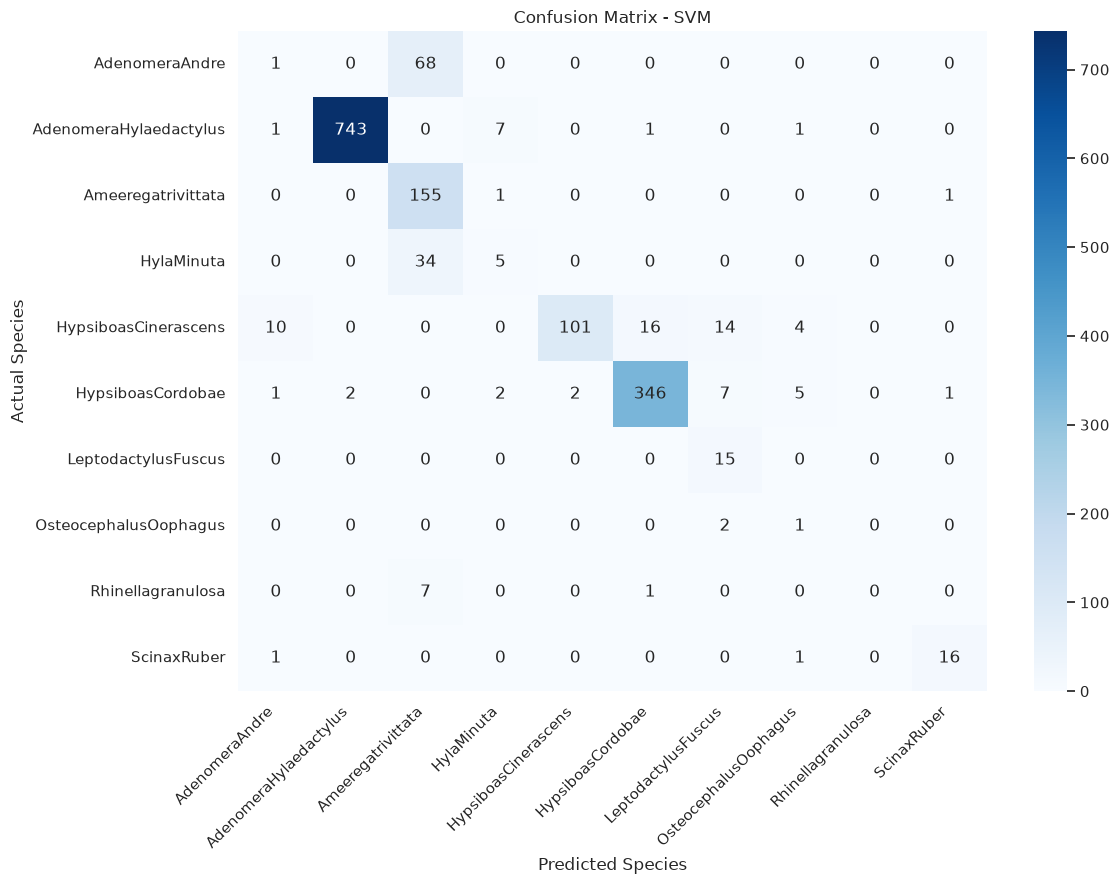

In [25]:
from sklearn.metrics import confusion_matrix, classification_report

class_labels = sorted(y.unique())

for model_name, model in trained_models.items():

    y_pred = model.predict(X_test)

    print(f"\n{'='*70}")
    print(f"Classification Report: {model_name}")
    print(f"{'='*70}")

    print(
        classification_report(
            y_test,
            y_pred,
            labels=class_labels,
            zero_division=0
        )
    )

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    plt.figure(figsize=(12, 9))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Species")
    plt.ylabel("Actual Species")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

Check recording availability for cross-validation

In [26]:
# Count independent recordings available for each species
cv_recording_summary = (
    df.iloc[train_idx]
    .groupby("Species")["RecordID"]
    .nunique()
    .sort_values()
)

print("Training recordings available per species:\n")
display(cv_recording_summary)

print("\nMinimum recordings per species:",
      cv_recording_summary.min())

Training recordings available per species:



Species
OsteocephalusOophagus      2
LeptodactylusFuscus        3
HypsiboasCinerascens       3
HypsiboasCordobae          3
Ameeregatrivittata         4
Rhinellagranulosa          4
ScinaxRuber                4
AdenomeraAndre             6
AdenomeraHylaedactylus     9
HylaMinuta                10
Name: RecordID, dtype: int64


Minimum recordings per species: 2


Hyperparameter Tuning Using Group-Aware Cross-Validation

In [27]:

all_species = set(y_train.unique())

for fold_number, (fold_train_idx, fold_val_idx) in enumerate(
    cv_splits, start=1
):

    fold_train_groups = set(groups_train.iloc[fold_train_idx])
    fold_val_groups = set(groups_train.iloc[fold_val_idx])

    fold_train_species = set(y_train.iloc[fold_train_idx].unique())
    fold_val_species = set(y_train.iloc[fold_val_idx].unique())

    print(f"\n{'='*50}")
    print(f"FOLD {fold_number}")
    print(f"{'='*50}")

    print("Training observations:", len(fold_train_idx))
    print("Validation observations:", len(fold_val_idx))

    print("Training recordings:", len(fold_train_groups))
    print("Validation recordings:", len(fold_val_groups))

    print("Training species:", len(fold_train_species))
    print("Validation species:", len(fold_val_species))

    print(
        "Common recordings:",
        len(fold_train_groups.intersection(fold_val_groups))
    )

    print("\nValidation class distribution:")
    print(
        y_train.iloc[fold_val_idx].value_counts().sort_index()
    )

    assert len(fold_train_groups.intersection(fold_val_groups)) == 0
    assert fold_train_species == all_species
    assert fold_val_species == all_species

print("\nBoth folds passed validation!")


FOLD 1
Training observations: 2818
Validation observations: 2804
Training recordings: 23
Validation recordings: 25
Training species: 10
Validation species: 10
Common recordings: 0

Validation class distribution:
Species
AdenomeraAndre             372
AdenomeraHylaedactylus    1390
Ameeregatrivittata         221
HylaMinuta                 135
HypsiboasCinerascens        68
HypsiboasCordobae          426
LeptodactylusFuscus         50
OsteocephalusOophagus       55
Rhinellagranulosa           15
ScinaxRuber                 72
Name: count, dtype: int64

FOLD 2
Training observations: 2804
Validation observations: 2818
Training recordings: 25
Validation recordings: 23
Training species: 10
Validation species: 10
Common recordings: 0

Validation class distribution:
Species
AdenomeraAndre             231
AdenomeraHylaedactylus    1335
Ameeregatrivittata         164
HylaMinuta                 136
HypsiboasCinerascens       259
HypsiboasCordobae          329
LeptodactylusFuscus        205
Osteo

## Hyperparameter tuning

Hyperparameter Tuning Using GridSearchCV

In [28]:
from sklearn.model_selection import GridSearchCV

param_grids = {

    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__class_weight": [None, "balanced"]
    },

    "Decision Tree": {
        "classifier__criterion": ["gini", "entropy"],
        "classifier__max_depth": [None, 10, 20, 30],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 4],
        "classifier__class_weight": [None, "balanced"]
    },

    "KNN": {
        "classifier__n_neighbors": [3, 5, 7, 9, 11],
        "classifier__weights": ["uniform", "distance"],
        "classifier__metric": ["euclidean", "manhattan"]
    },

    "Naive Bayes": {
        "classifier__var_smoothing": np.logspace(-12, -7, 6)
    },

    "SVM": {
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", "auto", 0.01, 0.1],
        "classifier__class_weight": [None, "balanced"]
    }
}

print("Hyperparameter search spaces defined.")

Hyperparameter search spaces defined.


Execute hyperparameter tuning

In [29]:
# Store tuned models and their search results
tuned_models = {}
tuning_results = {}

for model_name, model_pipeline in models.items():

    print(f"\n{'='*60}")
    print(f"Tuning: {model_name}")
    print(f"{'='*60}")

    # Use the same pipeline, with SVM probability estimation
    # disabled during hyperparameter tuning.
    search_model = clone(model_pipeline)

    grid_search = GridSearchCV(
        estimator=search_model,
        param_grid=param_grids[model_name],
        scoring="f1_macro",
        cv=cv_splits,
        n_jobs=-1,
        refit=True,
        verbose=1,
        error_score="raise"
    )

    start_time = time.time()

    grid_search.fit(X_train, y_train)

    tuning_time = time.time() - start_time

    tuned_models[model_name] = grid_search.best_estimator_

    tuning_results[model_name] = {
        "Best Parameters": grid_search.best_params_,
        "Best CV Macro F1": grid_search.best_score_,
        "Tuning Time (s)": tuning_time
    }

    print("\nBest parameters:")
    print(grid_search.best_params_)

    print(
        f"Best CV Macro F1: {grid_search.best_score_:.4f}"
    )

    print(f"Tuning time: {tuning_time:.2f} seconds")


Tuning: Logistic Regression
Fitting 2 folds for each of 10 candidates, totalling 20 fits

Best parameters:
{'classifier__C': 1, 'classifier__class_weight': None}
Best CV Macro F1: 0.5784
Tuning time: 93.60 seconds

Tuning: Decision Tree
Fitting 2 folds for each of 144 candidates, totalling 288 fits

Best parameters:
{'classifier__class_weight': None, 'classifier__criterion': 'entropy', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2}
Best CV Macro F1: 0.4650
Tuning time: 33.31 seconds

Tuning: KNN
Fitting 2 folds for each of 20 candidates, totalling 40 fits

Best parameters:
{'classifier__metric': 'manhattan', 'classifier__n_neighbors': 3, 'classifier__weights': 'distance'}
Best CV Macro F1: 0.5880
Tuning time: 7.06 seconds

Tuning: Naive Bayes
Fitting 2 folds for each of 6 candidates, totalling 12 fits

Best parameters:
{'classifier__var_smoothing': np.float64(1e-07)}
Best CV Macro F1: 0.5153
Tuning time: 0.88 seconds

Tuning: SVM


Tuning results

In [30]:
tuning_summary = pd.DataFrame([
    {
        "Model": model_name,
        "Best CV Macro F1": result["Best CV Macro F1"],
        "Best Parameters": str(result["Best Parameters"]),
        "Tuning Time (s)": result["Tuning Time (s)"]
    }
    for model_name, result in tuning_results.items()
])

display(tuning_summary)

,Model,Best CV Macro F1,Best Parameters,Tuning Time (s)
0,Logistic Regression,0.578411,"{'classifier__C': 1, 'classifier__class_weight...",93.596387
1,Decision Tree,0.464952,"{'classifier__class_weight': None, 'classifier...",33.307789
2,KNN,0.587974,"{'classifier__metric': 'manhattan', 'classifie...",7.057886
3,Naive Bayes,0.515250,{'classifier__var_smoothing': np.float64(1e-07)},0.879143
4,SVM,0.606901,"{'classifier__C': 1, 'classifier__class_weight...",19.599546


## Evaluation of Tuned Classification Models

Calibrate the tuned SVM

In [31]:
from sklearn.calibration import CalibratedClassifierCV

# Create a calibrated version of the tuned SVM
calibrated_svm = CalibratedClassifierCV(
    estimator=tuned_models["SVM"],
    method="sigmoid",
    cv=cv_splits,
    ensemble=False
)

# Fit using training data only
calibrated_svm.fit(X_train, y_train)

# Replace the tuned SVM with its calibrated version
tuned_models["SVM"] = calibrated_svm

print("Tuned SVM calibrated successfully.")


Caching the list of root modules, please wait!
(This will only be done once - type '%rehashx' to reset cache!)

Tuned SVM calibrated successfully.


Evaluate all tuned models

In [32]:
tuned_evaluation_results = []

for model_name, model in tuned_models.items():

    print(f"\nEvaluating {model_name}...")

    # Predict species labels
    y_pred = model.predict(X_test)

    # Obtain class probabilities
    y_prob = model.predict_proba(X_test)

    # Calculate required evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test,
        y_prob,
        labels=model.classes_,
        multi_class="ovr",
        average="macro"
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    tuned_evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Macro F1": macro_f1,
        "MCC": mcc
    })

    print(f"Accuracy:  {accuracy:.4f}")
    print(f"AUC:       {auc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"Macro F1:  {macro_f1:.4f}")
    print(f"MCC:       {mcc:.4f}")


Evaluating Logistic Regression...
Accuracy:  0.8976
AUC:       0.9748
Precision: 0.9085
Recall:    0.8976
F1 Score:  0.9003
Macro F1:  0.6377
MCC:       0.8552

Evaluating Decision Tree...
Accuracy:  0.8296
AUC:       0.8393
Precision: 0.8834
Recall:    0.8296
F1 Score:  0.8495
Macro F1:  0.5323
MCC:       0.7619

Evaluating KNN...
Accuracy:  0.9078
AUC:       0.9334
Precision: 0.9283
Recall:    0.9078
F1 Score:  0.9129
Macro F1:  0.6732
MCC:       0.8699

Evaluating Naive Bayes...
Accuracy:  0.8169
AUC:       0.9633
Precision: 0.8797
Recall:    0.8169
F1 Score:  0.8385
Macro F1:  0.5642
MCC:       0.7490

Evaluating SVM...
Accuracy:  0.9097
AUC:       0.9832
Precision: 0.9069
Recall:    0.9097
F1 Score:  0.9050
Macro F1:  0.5888
MCC:       0.8724


Tuned model comparison table

In [33]:
tuned_results_df = pd.DataFrame(
    tuned_evaluation_results
).set_index("Model")

display(tuned_results_df.style.format("{:.4f}"))

,Accuracy,AUC,Precision,Recall,F1 Score,Macro F1,MCC
Model,,,,,,,
Logistic Regression,0.8976,0.9748,0.9085,0.8976,0.9003,0.6377,0.8552
Decision Tree,0.8296,0.8393,0.8834,0.8296,0.8495,0.5323,0.7619
KNN,0.9078,0.9334,0.9283,0.9078,0.9129,0.6732,0.8699
Naive Bayes,0.8169,0.9633,0.8797,0.8169,0.8385,0.5642,0.7490
SVM,0.9097,0.9832,0.9069,0.9097,0.9050,0.5888,0.8724


Compare baseline and tuned performance

In [34]:
baseline_comparison = results_df[
    ["Accuracy", "AUC", "F1 Score", "MCC"]
].add_suffix("_Baseline")

tuned_comparison = tuned_results_df[
    ["Accuracy", "AUC", "F1 Score", "MCC"]
].add_suffix("_Tuned")

performance_comparison = pd.concat(
    [baseline_comparison, tuned_comparison],
    axis=1
)

display(performance_comparison.style.format("{:.4f}"))

,Accuracy_Baseline,AUC_Baseline,F1 Score_Baseline,MCC_Baseline,Accuracy_Tuned,AUC_Tuned,F1 Score_Tuned,MCC_Tuned
Model,,,,,,,,
Logistic Regression,0.8976,0.9748,0.9003,0.8552,0.8976,0.9748,0.9003,0.8552
Decision Tree,0.8659,0.8611,0.8773,0.8118,0.8296,0.8393,0.8495,0.7619
KNN,0.9059,0.9367,0.9092,0.8671,0.9078,0.9334,0.9129,0.8699
Naive Bayes,0.8252,0.9600,0.8393,0.7615,0.8169,0.9633,0.8385,0.7490
SVM,0.8792,0.9813,0.8655,0.8306,0.9097,0.9832,0.9050,0.8724


In [35]:
macro_f1_comparison = pd.DataFrame({
    "Baseline Macro F1": [
        f1_score(
            y_test,
            trained_models[name].predict(X_test),
            average="macro",
            zero_division=0
        )
        for name in trained_models
    ],
    "Tuned Macro F1": tuned_results_df["Macro F1"]
}, index=trained_models.keys())

macro_f1_comparison["Improvement"] = (
    macro_f1_comparison["Tuned Macro F1"]
    - macro_f1_comparison["Baseline Macro F1"]
)

display(macro_f1_comparison.style.format("{:.4f}"))

,Baseline Macro F1,Tuned Macro F1,Improvement
Logistic Regression,0.6377,0.6377,0.0000
Decision Tree,0.6296,0.5323,-0.0973
KNN,0.6888,0.6732,-0.0155
Naive Bayes,0.5581,0.5642,0.0061
SVM,0.5288,0.5888,0.0600


Classification reports for tuned models

In [36]:
from sklearn.metrics import classification_report

for model_name, model in tuned_models.items():

    print("\n" + "=" * 70)
    print(f"Classification Report: {model_name}")
    print("=" * 70)

    y_pred = model.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=model.classes_,
            zero_division=0
        )
    )


Classification Report: Logistic Regression
                        precision    recall  f1-score   support

        AdenomeraAndre       0.41      0.35      0.38        69
AdenomeraHylaedactylus       1.00      0.98      0.99       753
    Ameeregatrivittata       0.78      0.94      0.85       157
            HylaMinuta       0.25      0.18      0.21        39
  HypsiboasCinerascens       0.92      0.90      0.91       145
     HypsiboasCordobae       0.99      0.90      0.94       366
   LeptodactylusFuscus       0.33      0.73      0.46        15
 OsteocephalusOophagus       0.08      0.33      0.12         3
     Rhinellagranulosa       0.50      0.88      0.64         8
           ScinaxRuber       0.78      1.00      0.88        18

              accuracy                           0.90      1573
             macro avg       0.60      0.72      0.64      1573
          weighted avg       0.91      0.90      0.90      1573


Classification Report: Decision Tree
                   

Confusion matrices for tuned models

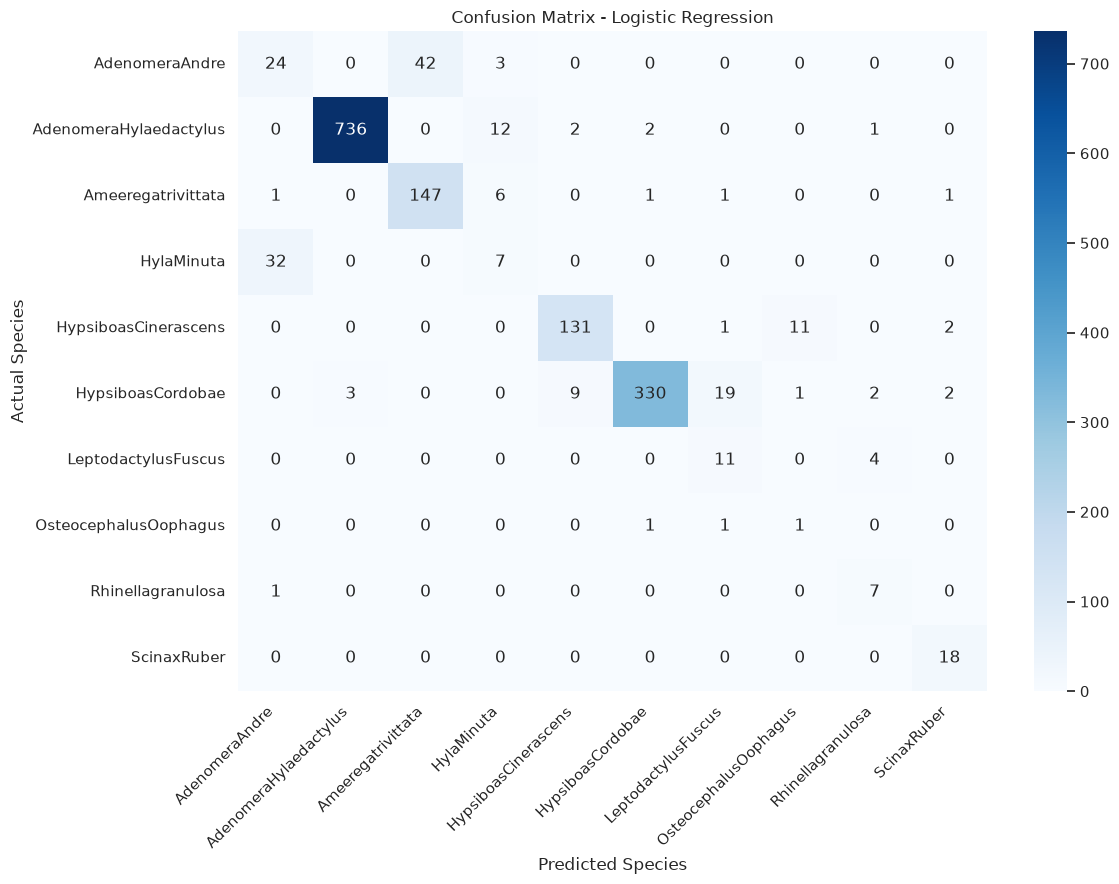

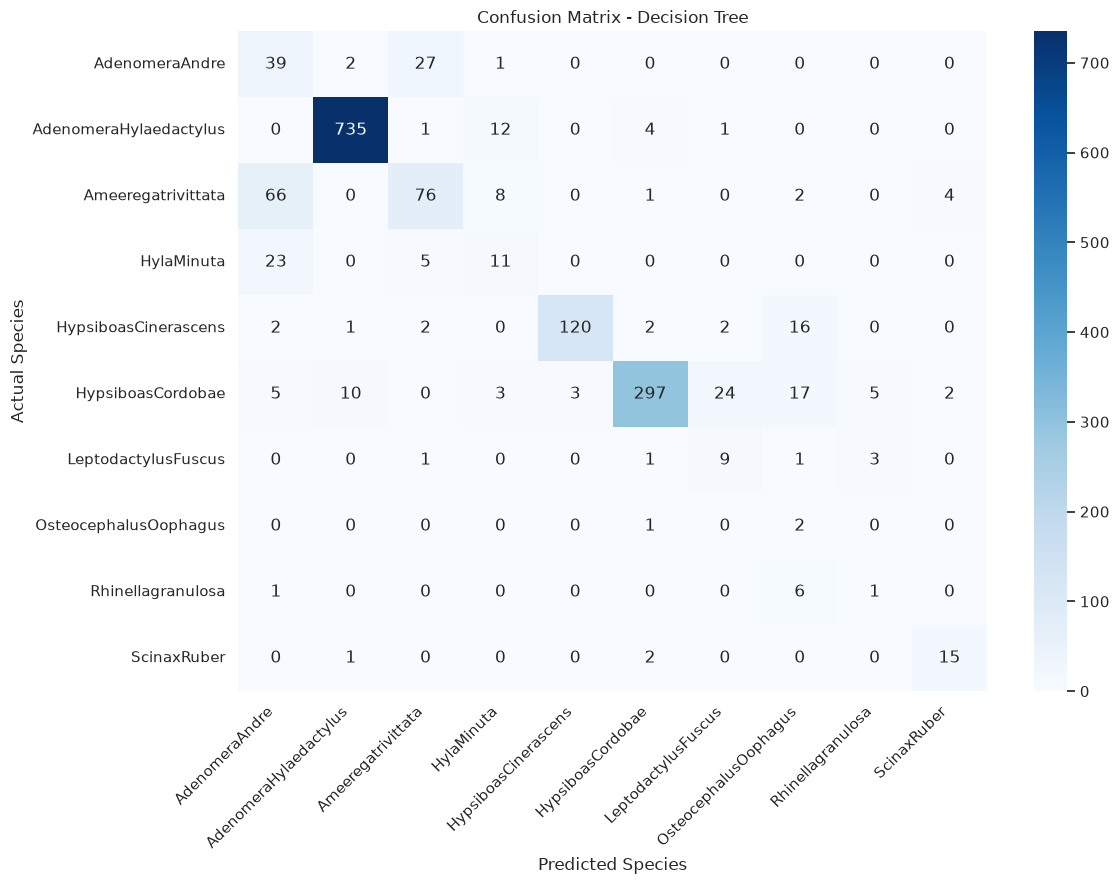

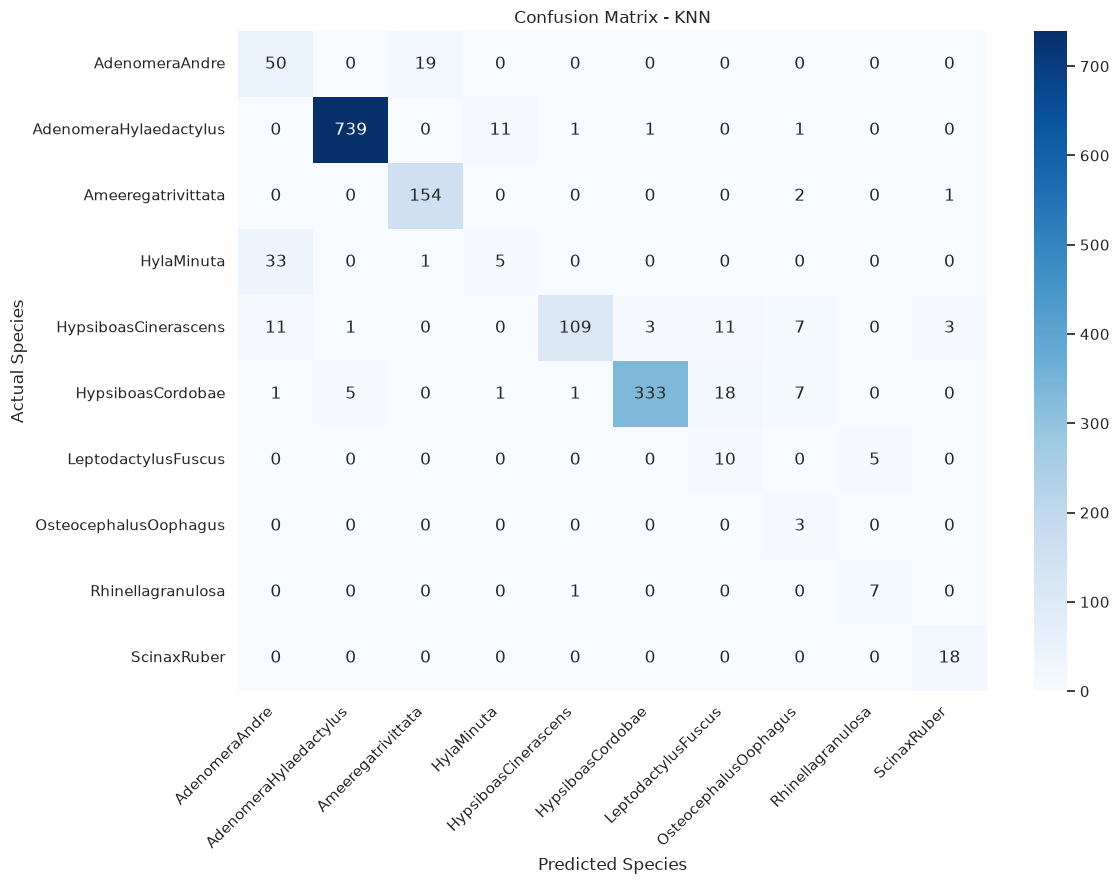

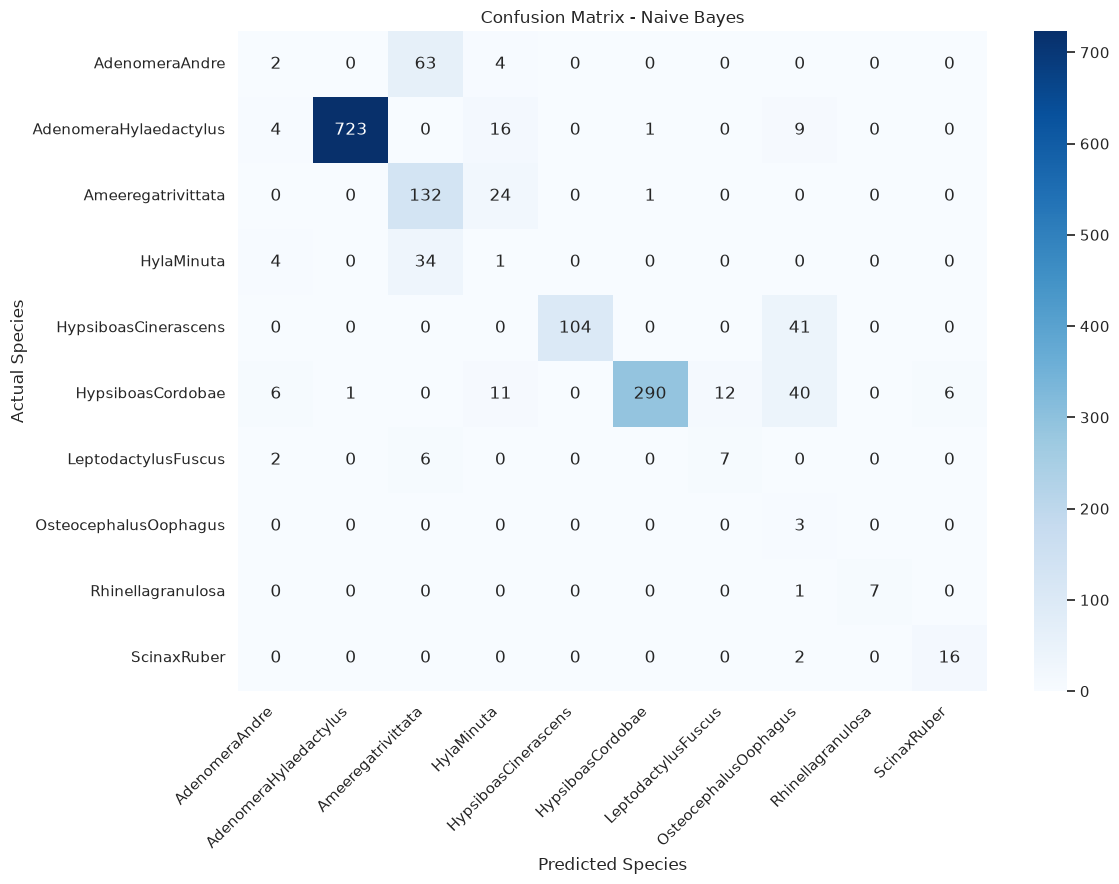

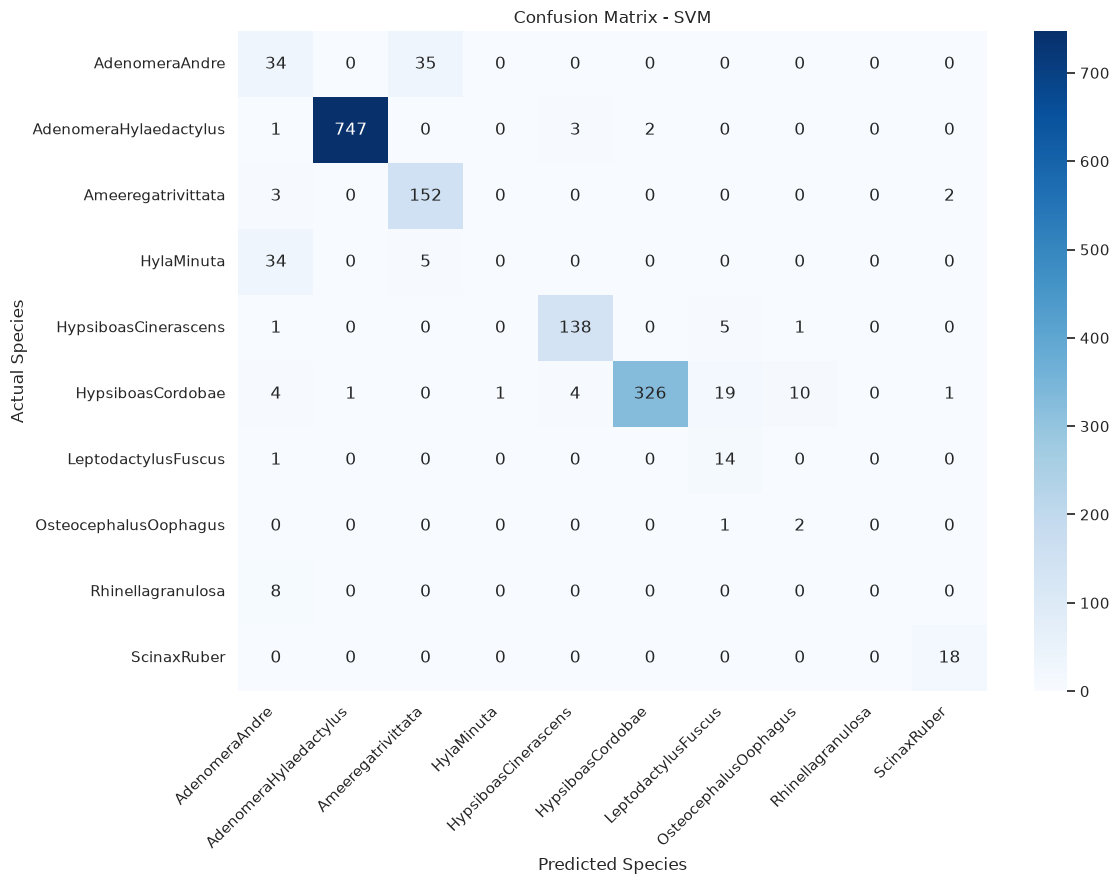

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

class_names = sorted(y.unique())

for model_name, model in tuned_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_names
    )

    plt.figure(figsize=(12, 9))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Species")
    plt.ylabel("Actual Species")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

Save Final Tuned Models

In [38]:
# Save the final tuned models for deployment
os.makedirs("models", exist_ok=True)

for model_name, model in tuned_models.items():

    file_path = os.path.join(
        "models",
        model_files[model_name]
    )

    joblib.dump(model, file_path)

    print(f"Saved final {model_name}: {file_path}")

Saved final Logistic Regression: models/logistic_regression.joblib
Saved final Decision Tree: models/decision_tree.joblib
Saved final KNN: models/knn.joblib
Saved final Naive Bayes: models/naive_bayes.joblib
Saved final SVM: models/svm.joblib


Verify the saved models

In [39]:
# Load each saved model and verify that it can make predictions
for model_name, filename in model_files.items():

    file_path = os.path.join("models", filename)

    loaded_model = joblib.load(file_path)

    predictions = loaded_model.predict(X_test.head(5))

    print(f"{model_name}:")
    print("Predictions:", predictions)
    print("Model loaded successfully.\n")

Logistic Regression:
Predictions: ['Ameeregatrivittata' 'Ameeregatrivittata' 'Ameeregatrivittata'
 'AdenomeraAndre' 'AdenomeraAndre']
Model loaded successfully.

Decision Tree:
Predictions: ['Ameeregatrivittata' 'Ameeregatrivittata' 'AdenomeraAndre'
 'AdenomeraAndre' 'AdenomeraAndre']
Model loaded successfully.

KNN:
Predictions: ['AdenomeraAndre' 'AdenomeraAndre' 'AdenomeraAndre' 'AdenomeraAndre'
 'AdenomeraAndre']
Model loaded successfully.

Naive Bayes:
Predictions: ['Ameeregatrivittata' 'Ameeregatrivittata' 'Ameeregatrivittata'
 'Ameeregatrivittata' 'Ameeregatrivittata']
Model loaded successfully.

SVM:
Predictions: ['Ameeregatrivittata' 'Ameeregatrivittata' 'AdenomeraAndre'
 'AdenomeraAndre' 'AdenomeraAndre']
Model loaded successfully.



## Export Test Dataset for Streamlit Application

Generate test_data.csv

In [40]:
import pandas as pd

# Combine the held-out MFCC features and their actual species labels
test_data = pd.concat(
    [
        X_test.reset_index(drop=True),
        y_test.reset_index(drop=True).rename("Species")
    ],
    axis=1
)

# Save the test dataset in the project root directory
test_data.to_csv("test_data.csv", index=False)

print("Test dataset exported successfully!")
print("File: test_data.csv")
print("Shape:", test_data.shape)

print("\nFirst five rows:")
display(test_data.head())

print("\nSpecies distribution:")
print(test_data["Species"].value_counts().sort_index())

Test dataset exported successfully!
File: test_data.csv
Shape: (1573, 23)

First five rows:


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,MFCCs_11,MFCCs_12,MFCCs_13,MFCCs_14,MFCCs_15,MFCCs_16,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Species
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,0.188654,-0.075622,-0.156436,0.082245,0.135752,-0.024017,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,AdenomeraAndre
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,0.270958,-0.095004,-0.254341,0.022786,0.163320,0.012022,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,AdenomeraAndre
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,0.266064,-0.072827,-0.237384,0.050791,0.207338,0.083536,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,AdenomeraAndre
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,0.267279,-0.162258,-0.317084,-0.011567,0.100413,-0.050224,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,AdenomeraAndre
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,0.332695,-0.100749,-0.298524,0.037439,0.219153,0.062837,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,AdenomeraAndre



Species distribution:
Species
AdenomeraAndre             69
AdenomeraHylaedactylus    753
Ameeregatrivittata        157
HylaMinuta                 39
HypsiboasCinerascens      145
HypsiboasCordobae         366
LeptodactylusFuscus        15
OsteocephalusOophagus       3
Rhinellagranulosa           8
ScinaxRuber                18
Name: count, dtype: int64


Validate the exported dataset

In [41]:
# Verify that the exported CSV can be loaded correctly
loaded_test_data = pd.read_csv("test_data.csv")

# Check the number of features and target column
assert loaded_test_data.shape[1] == 23
assert "Species" in loaded_test_data.columns

# Check that all required MFCC features are present
assert set(feature_columns).issubset(loaded_test_data.columns)

# Check for missing values
assert loaded_test_data.isnull().sum().sum() == 0

# Verify that the exported labels match the original test labels
assert loaded_test_data["Species"].equals(
    y_test.reset_index(drop=True)
)

print("All test dataset validation checks passed!")

All test dataset validation checks passed!
